In [1]:

import os
import pandas as pd
import numpy as np
import sys
import subprocess

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FOLD_DIR = os.path.join(BASE_DIR, "01_Folds")
MODEL_DIR = os.path.join(BASE_DIR, "02_Models")
PRED_DIR = os.path.join(BASE_DIR, "03_Predictions")
PLOT_DIR = os.path.join(BASE_DIR, "04_Plots")
RESULT_DIR = os.path.join(BASE_DIR, "05_Results")
FINAL_DIR = os.path.join(BASE_DIR, "06_Final_Model")
SCREEN_DIR = os.path.join(BASE_DIR, "07_Screening_991")
DATA_DIR = os.path.join(BASE_DIR, "00_Dataset")
LOG_DIR = os.path.join(BASE_DIR, "08_Logs")

directories = [
    BASE_DIR,
    FOLD_DIR,
    MODEL_DIR,
    PRED_DIR,
    PLOT_DIR,
    RESULT_DIR,
    FINAL_DIR,
    SCREEN_DIR,
    DATA_DIR,
    LOG_DIR
]

for directory in directories:
    os.makedirs(directory, exist_ok=True)

print("=" * 55)
print("D-MPNN PROJECT DIRECTORY")
print("=" * 55)

for directory in directories:
    print(directory)

print("\nALL DIRECTORIES CREATED SUCCESSFULLY")


D-MPNN PROJECT DIRECTORY
/data/Zira/Chemprop_Kd_80/DMPNN
/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds
/data/Zira/Chemprop_Kd_80/DMPNN/02_Models
/data/Zira/Chemprop_Kd_80/DMPNN/03_Predictions
/data/Zira/Chemprop_Kd_80/DMPNN/04_Plots
/data/Zira/Chemprop_Kd_80/DMPNN/05_Results
/data/Zira/Chemprop_Kd_80/DMPNN/06_Final_Model
/data/Zira/Chemprop_Kd_80/DMPNN/07_Screening_991
/data/Zira/Chemprop_Kd_80/DMPNN/00_Dataset
/data/Zira/Chemprop_Kd_80/DMPNN/08_Logs

ALL DIRECTORIES CREATED SUCCESSFULLY


In [2]:

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "devitanuraljazira/Model-ML-DL/refs/heads/main/"
    "USP5_Kd_80_fixed.csv"
)

DATA_PATH = os.path.join(
    DATA_DIR,
    "USP5_Kd_80_fixed.csv"
)

df = pd.read_csv(DATA_URL)

df.to_csv(DATA_PATH, index=False)

print("DATASET LOADED")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

print("\nDataset saved:")
print(DATA_PATH)


DATASET LOADED
Dataset shape: (80, 3)
Columns: ['Molecule ChEMBL ID', 'Smiles', 'pKd']


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL4451435,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
3,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
4,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373



Dataset saved:
/data/Zira/Chemprop_Kd_80/DMPNN/00_Dataset/USP5_Kd_80_fixed.csv


In [3]:

from rdkit import Chem
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")

required_columns = [
    "Molecule ChEMBL ID",
    "Smiles",
    "pKd"
]

assert all(
    col in df.columns for col in required_columns
)

df["pKd"] = pd.to_numeric(
    df["pKd"],
    errors="coerce"
)

def check_smiles(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    return mol is not None

valid_smiles = df["Smiles"].apply(check_smiles)

print("DATASET VALIDATION")
print("=" * 45)

print("Total compounds:", len(df))
print("Valid SMILES:", valid_smiles.sum())
print("Invalid SMILES:", (~valid_smiles).sum())

print(
    "Missing values:",
    df[required_columns].isnull().sum().sum()
)

print(
    "Duplicate SMILES:",
    df["Smiles"].duplicated().sum()
)

print("\npKd statistics:")
display(df["pKd"].describe())

assert len(df) == 80
assert valid_smiles.all()
assert df[required_columns].notna().all().all()
assert df["Smiles"].is_unique

print("\nDATASET READY FOR D-MPNN")


DATASET VALIDATION
Total compounds: 80
Valid SMILES: 80
Invalid SMILES: 0
Missing values: 0
Duplicate SMILES: 0

pKd statistics:


count    80.000000
mean      4.121417
std       0.636259
min       3.031517
25%       3.643698
50%       4.099641
75%       4.531994
max       5.552842
Name: pKd, dtype: float64


DATASET READY FOR D-MPNN


In [4]:

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold

# Main directory
BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

DATA_PATH = os.path.join(
    BASE_DIR,
    "00_Dataset",
    "USP5_Kd_80_fixed.csv"
)

FOLD_DIR = os.path.join(BASE_DIR, "01_Folds")
RESULT_DIR = os.path.join(BASE_DIR, "05_Results")

os.makedirs(FOLD_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH)

# KFold configuration
SEED = 42
N_SPLITS = 5

kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

fold_summary = []
fold_assignments = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(df),
    start=1
):

    train_df = df.iloc[train_idx].copy()
    val_df = df.iloc[val_idx].copy()

    fold_path = os.path.join(
        FOLD_DIR,
        f"Fold{fold:02d}"
    )

    os.makedirs(fold_path, exist_ok=True)

    # Save training data
    train_df.to_csv(
        os.path.join(fold_path, "train.csv"),
        index=False
    )

    # Save validation data
    val_df.to_csv(
        os.path.join(fold_path, "validation.csv"),
        index=False
    )

    # Record assignments
    for idx in train_idx:
        fold_assignments.append({
            "Index": idx,
            "Fold": fold,
            "Partition": "Train"
        })

    for idx in val_idx:
        fold_assignments.append({
            "Index": idx,
            "Fold": fold,
            "Partition": "Validation"
        })

    fold_summary.append({
        "Fold": fold,
        "Train_Size": len(train_df),
        "Validation_Size": len(val_df),
        "Train_File": os.path.join(
            fold_path, "train.csv"
        ),
        "Validation_File": os.path.join(
            fold_path, "validation.csv"
        )
    })

# Create summary
fold_summary_df = pd.DataFrame(fold_summary)

display(fold_summary_df)

# Save summary
fold_summary_df.to_csv(
    os.path.join(RESULT_DIR, "Fold_Summary.csv"),
    index=False
)

# Save complete fold assignments
assignment_df = pd.DataFrame(fold_assignments)

assignment_df.to_csv(
    os.path.join(RESULT_DIR, "Fold_Assignments.csv"),
    index=False
)

print("\nTOTAL FOLDS:", len(fold_summary_df))
print(
    "TOTAL VALIDATION RECORDS:",
    fold_summary_df["Validation_Size"].sum()
)

print("\nFOLD GENERATION COMPLETED")


,Fold,Train_Size,Validation_Size,Train_File,Validation_File
0,1,64,16,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...
1,2,64,16,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...
2,3,64,16,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...
3,4,64,16,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...
4,5,64,16,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...,/data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold0...



TOTAL FOLDS: 5
TOTAL VALIDATION RECORDS: 80

FOLD GENERATION COMPLETED


In [5]:

print("=" * 55)
print("K-FOLD VALIDATION CHECK")
print("=" * 55)

for fold in range(1, 6):

    fold_path = os.path.join(
        FOLD_DIR,
        f"Fold{fold:02d}"
    )

    train_df = pd.read_csv(
        os.path.join(fold_path, "train.csv")
    )

    val_df = pd.read_csv(
        os.path.join(fold_path, "validation.csv")
    )

    train_ids = set(train_df["Molecule ChEMBL ID"])
    val_ids = set(val_df["Molecule ChEMBL ID"])

    assert len(train_df) == 64
    assert len(val_df) == 16

    assert train_ids.isdisjoint(val_ids)

    print(
        f"Fold {fold}: "
        f"Train={len(train_df)}, "
        f"Validation={len(val_df)}, "
        f"Overlap={len(train_ids & val_ids)}"
    )

# Every compound must appear once in validation
validation_counts = (
    assignment_df[
        assignment_df["Partition"] == "Validation"
    ]["Index"]
    .value_counts()
)

assert len(validation_counts) == 80
assert (validation_counts == 1).all()

print("\nALL FOLDS VERIFIED")
print("Each compound appears once in validation.")
print("No train-validation overlap.")


K-FOLD VALIDATION CHECK
Fold 1: Train=64, Validation=16, Overlap=0
Fold 2: Train=64, Validation=16, Overlap=0
Fold 3: Train=64, Validation=16, Overlap=0
Fold 4: Train=64, Validation=16, Overlap=0
Fold 5: Train=64, Validation=16, Overlap=0

ALL FOLDS VERIFIED
Each compound appears once in validation.
No train-validation overlap.


In [6]:

import os
import json
import pandas as pd

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

CONFIG_DIR = os.path.join(
    BASE_DIR,
    "05_Results",
    "Configuration"
)

os.makedirs(CONFIG_DIR, exist_ok=True)

CONFIG = {
    "architecture": "D-MPNN",
    "task": "regression",
    "target": "pKd",

    "hidden_dim": 300,
    "depth": 3,
    "dropout": 0.0,

    "batch_size": 16,
    "epochs": 100,
    "patience": 20,

    "aggregation": "norm",
    "aggregation_norm": 100,

    "featurizer": "V2",
    "tracking_metric": "rmse",

    "cross_validation": {
        "method": "KFold",
        "n_splits": 5,
        "shuffle": True,
        "random_state": 42,
        "training_size": 64,
        "validation_size": 16
    },

    "training": {
        "pytorch_seed": 42,
        "accelerator": "gpu",
        "devices": 1
    },

    "software": {
        "chemprop": "2.3.1",
        "pytorch": "2.5.1+cu124",
        "python": "3.11.18"
    }
}

config_path = os.path.join(
    CONFIG_DIR,
    "DMPNN_5Fold_Seed42_Config.json"
)

with open(config_path, "w") as f:
    json.dump(CONFIG, f, indent=4)

display(
    pd.DataFrame(
        CONFIG.items(),
        columns=["Parameter", "Value"]
    )
)

print("\nCONFIGURATION SAVED")
print(config_path)


,Parameter,Value
0,architecture,D-MPNN
1,task,regression
2,target,pKd
3,hidden_dim,300
4,depth,3
5,dropout,0.0
6,batch_size,16
7,epochs,100
8,patience,20
9,aggregation,norm



CONFIGURATION SAVED
/data/Zira/Chemprop_Kd_80/DMPNN/05_Results/Configuration/DMPNN_5Fold_Seed42_Config.json


In [7]:

import sys
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "-c",
        "from chemprop.cli.main import main; main()",
        "train",
        "--help"
    ],
    capture_output=True,
    text=True
)

help_text = result.stdout + result.stderr

print("TRACKING METRIC CHECK")
print("=" * 45)

for line in help_text.splitlines():
    if "tracking-metric" in line.lower():
        print(line)

print("\nCLI return code:", result.returncode)

assert result.returncode == 0
assert "tracking-metric" in help_text.lower()

print("\nCHEMPROP CONFIGURATION VERIFIED")


TRACKING METRIC CHECK
                [--tracking-metric TRACKING_METRIC] [--show-individual-scores]
  --tracking-metric TRACKING_METRIC

CLI return code: 0

CHEMPROP CONFIGURATION VERIFIED


In [8]:

import os
import pandas as pd

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FOLD_PATH = os.path.join(
    BASE_DIR,
    "01_Folds",
    "Fold01"
)

TRAIN_FILE = os.path.join(FOLD_PATH, "train.csv")
VAL_FILE = os.path.join(FOLD_PATH, "validation.csv")

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_Models",
    "Fold01"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

train_df = pd.read_csv(TRAIN_FILE)
val_df = pd.read_csv(VAL_FILE)

print("FOLD 01 INPUT CHECK")
print("=" * 50)

print("Training file:", TRAIN_FILE)
print("Validation file:", VAL_FILE)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nTraining columns:", train_df.columns.tolist())
print("Validation columns:", val_df.columns.tolist())

print("\nTraining preview:")
display(train_df.head(3))

print("\nValidation preview:")
display(val_df.head(3))

assert len(train_df) == 64
assert len(val_df) == 16
assert "Smiles" in train_df.columns
assert "pKd" in train_df.columns

print("\nFOLD 01 INPUT READY")
print("Output directory:", OUTPUT_DIR)


FOLD 01 INPUT CHECK
Training file: /data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold01/train.csv
Validation file: /data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold01/validation.csv
Training shape: (64, 3)
Validation shape: (16, 3)

Training columns: ['Molecule ChEMBL ID', 'Smiles', 'pKd']
Validation columns: ['Molecule ChEMBL ID', 'Smiles', 'pKd']

Training preview:


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL4451435,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
1,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
2,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272



Validation preview:


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
2,CHEMBL4463491,O=C(O)CCC(=O)c1cccs1,3.075721



FOLD 01 INPUT READY
Output directory: /data/Zira/Chemprop_Kd_80/DMPNN/02_Models/Fold01


In [9]:

import os
import sys
import subprocess

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FOLD_DIR = os.path.join(
    BASE_DIR,
    "01_Folds",
    "Fold01"
)

TRAIN_FILE = os.path.join(
    FOLD_DIR,
    "train.csv"
)

VAL_FILE = os.path.join(
    FOLD_DIR,
    "validation.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_Models",
    "Fold01"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Verify input files
assert os.path.exists(TRAIN_FILE)
assert os.path.exists(VAL_FILE)

command = [
    sys.executable,
    "-c",
    "from chemprop.cli.main import main; main()",

    "train",

    # Three input files following notebook workflow
    "--data-path",
    TRAIN_FILE,
    VAL_FILE,
    VAL_FILE,

    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",

    "--task-type", "regression",

    # Evaluation metrics
    "--metrics", "rmse", "mae", "r2",
    "--tracking-metric", "rmse",

    # D-MPNN configuration
    "--multi-hot-atom-featurizer-mode", "V2",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.0",

    "--aggregation", "norm",
    "--aggregation-norm", "100",

    # Training configuration
    "--batch-size", "16",
    "--epochs", "100",
    "--patience", "20",

    # Reproducibility and GPU
    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",

    # Output
    "--output-dir", OUTPUT_DIR
]

print("=" * 60)
print("D-MPNN TRAINING")
print("Fold 01 | Random 5-Fold | Seed 42")
print("=" * 60)

print("\nTraining file:", TRAIN_FILE)
print("Validation file:", VAL_FILE)
print("Output directory:", OUTPUT_DIR)

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

# Save training log
log_path = os.path.join(
    OUTPUT_DIR,
    "training_log.txt"
)

with open(log_path, "w") as f:
    f.write(result.stdout)
    f.write("\n\nSTDERR:\n")
    f.write(result.stderr)

print("\nReturn code:", result.returncode)

print("\nTRAINING OUTPUT:")
print(result.stdout[-8000:])

if result.stderr:
    print("\nERROR OUTPUT:")
    print(result.stderr[-4000:])

print("\nLog saved:", log_path)
print("\nTRAINING PROCESS FINISHED")


D-MPNN TRAINING
Fold 01 | Random 5-Fold | Seed 42

Training file: /data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold01/train.csv
Validation file: /data/Zira/Chemprop_Kd_80/DMPNN/01_Folds/Fold01/validation.csv
Output directory: /data/Zira/Chemprop_Kd_80/DMPNN/02_Models/Fold01

Return code: 0

TRAINING OUTPUT:
                                        0.229 val_loss:   
                                                              0.275             
                                                              train_loss_epoch: 
                                                              0.302             
Epoch 65/99 ━━━━━━━━━━━━━━━━━ 4/4 0:00:00 • 0:00:00 83.89it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.229 val_loss:   
                                                              0.275             
                                                              train_l

In [10]:

import os

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_Models",
    "Fold01"
)

print("=" * 55)
print("FOLD 01 OUTPUT VERIFICATION")
print("=" * 55)

for root, dirs, files in os.walk(OUTPUT_DIR):

    level = root.replace(OUTPUT_DIR, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in files:
        print(f"{indent}    {filename}")

BEST_MODEL = os.path.join(
    OUTPUT_DIR,
    "model_0",
    "best.pt"
)

PREDICTION_FILE = os.path.join(
    OUTPUT_DIR,
    "model_0",
    "test_predictions.csv"
)

print("\nBEST MODEL EXISTS:", os.path.exists(BEST_MODEL))
print("PREDICTION FILE EXISTS:", os.path.exists(PREDICTION_FILE))

if os.path.exists(PREDICTION_FILE):

    import pandas as pd

    pred_df = pd.read_csv(PREDICTION_FILE)

    print("\nPREDICTION SHAPE:", pred_df.shape)
    print("COLUMNS:", pred_df.columns.tolist())

    display(pred_df.head())

print("\nVERIFICATION COMPLETED")


FOLD 01 OUTPUT VERIFICATION
Fold01/
    config.toml
    training_log.txt
    model_0/
        test_predictions.csv
        best.pt
        checkpoints/
            last.ckpt
            best-epoch=46-val_rmse=0.49.ckpt
        trainer_logs/
            version_0/
                hparams.yaml
                metrics.csv

BEST MODEL EXISTS: True
PREDICTION FILE EXISTS: True

PREDICTION SHAPE: (16, 2)
COLUMNS: ['Smiles', 'pKd']


,Smiles,pKd
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,4.495879
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.313466
2,O=C(O)CCC(=O)c1cccs1,3.387729
3,Cc1cccc2c(=O)n(CC(=O)O)cnc12,3.877315
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CC=C(c3ccccc3)CC...,3.829645



VERIFICATION COMPLETED


In [11]:

import os
import sys
import subprocess

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FOLD_DIR = os.path.join(
    BASE_DIR,
    "01_Folds",
    "Fold02"
)

TRAIN_FILE = os.path.join(
    FOLD_DIR,
    "train.csv"
)

VAL_FILE = os.path.join(
    FOLD_DIR,
    "validation.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_Models",
    "Fold02"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.exists(TRAIN_FILE)
assert os.path.exists(VAL_FILE)

command = [
    sys.executable,
    "-c",
    "from chemprop.cli.main import main; main()",
    "train",

    "--data-path",
    TRAIN_FILE,
    VAL_FILE,
    VAL_FILE,

    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",

    "--task-type", "regression",
    "--metrics", "rmse", "mae", "r2",
    "--tracking-metric", "rmse",

    "--multi-hot-atom-featurizer-mode", "V2",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.0",

    "--aggregation", "norm",
    "--aggregation-norm", "100",

    "--batch-size", "16",
    "--epochs", "100",
    "--patience", "20",

    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",

    "--output-dir", OUTPUT_DIR
]

print("=" * 55)
print("D-MPNN TRAINING")
print("FOLD 02 | RANDOM 5-FOLD | SEED 42")
print("=" * 55)

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

with open(
    os.path.join(OUTPUT_DIR, "training_log.txt"),
    "w"
) as f:
    f.write(result.stdout)
    f.write("\n\nSTDERR:\n")
    f.write(result.stderr)

print("\nReturn code:", result.returncode)
print(result.stdout[-8000:])

if result.stderr:
    print("\nERROR OUTPUT:")
    print(result.stderr[-3000:])

print("\nOUTPUT DIRECTORY:")
print(OUTPUT_DIR)

print("\nTRAINING FINISHED")


D-MPNN TRAINING
FOLD 02 | RANDOM 5-FOLD | SEED 42

Return code: 0
             0.262             
                                                              train_loss_epoch: 
                                                              0.329             
Epoch 58/99 ━━━━━━━━━━━━━━━━━ 4/4 0:00:00 • 0:00:00 82.53it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.198 val_loss:   
                                                              0.262             
                                                              train_loss_epoch: 
                                                              0.329             
Epoch 58/99 ━━━━━━━━━━━━━━━━━ 4/4 0:00:00 • 0:00:00 82.53it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.198 val_loss:   
           

In [12]:

import os
import sys
import subprocess

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FOLD_DIR = os.path.join(
    BASE_DIR,
    "01_Folds",
    "Fold03"
)

TRAIN_FILE = os.path.join(FOLD_DIR, "train.csv")
VAL_FILE = os.path.join(FOLD_DIR, "validation.csv")

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_Models",
    "Fold03"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.exists(TRAIN_FILE)
assert os.path.exists(VAL_FILE)

command = [
    sys.executable,
    "-c",
    "from chemprop.cli.main import main; main()",
    "train",

    "--data-path",
    TRAIN_FILE,
    VAL_FILE,
    VAL_FILE,

    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",

    "--task-type", "regression",
    "--metrics", "rmse", "mae", "r2",
    "--tracking-metric", "rmse",

    "--multi-hot-atom-featurizer-mode", "V2",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.0",

    "--aggregation", "norm",
    "--aggregation-norm", "100",

    "--batch-size", "16",
    "--epochs", "100",
    "--patience", "20",

    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",

    "--output-dir", OUTPUT_DIR
]

print("=" * 55)
print("D-MPNN TRAINING")
print("FOLD 03 | RANDOM 5-FOLD | SEED 42")
print("=" * 55)

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

with open(
    os.path.join(OUTPUT_DIR, "training_log.txt"),
    "w"
) as f:
    f.write(result.stdout)
    f.write("\n\nSTDERR:\n")
    f.write(result.stderr)

print("Return code:", result.returncode)
print(result.stdout[-8000:])

if result.stderr:
    print("\nERROR OUTPUT:")
    print(result.stderr[-3000:])

print("\nOUTPUT DIRECTORY:", OUTPUT_DIR)
print("TRAINING FINISHED")


D-MPNN TRAINING
FOLD 03 | RANDOM 5-FOLD | SEED 42
Return code: 0
                      0.363 val_loss:   
                                                              1.202             
                                                              train_loss_epoch: 
                                                              0.320             
Epoch 64/99 ━━━━━━━━━━━━╸━━━━ 3/4 0:00:00 • 0:00:01 85.18it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.184 val_loss:   
                                                              1.202             
                                                              train_loss_epoch: 
                                                              0.320             
Epoch 64/99 ━━━━━━━━━━━━━━━━━ 4/4 0:00:00 • 0:00:00 84.76it/s v_num: 0.000      
                                                              train_loss_step:  
   

In [13]:

import os
import sys
import subprocess

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FOLD_DIR = os.path.join(
    BASE_DIR,
    "01_Folds",
    "Fold04"
)

TRAIN_FILE = os.path.join(FOLD_DIR, "train.csv")
VAL_FILE = os.path.join(FOLD_DIR, "validation.csv")

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_Models",
    "Fold04"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.exists(TRAIN_FILE)
assert os.path.exists(VAL_FILE)

command = [
    sys.executable,
    "-c",
    "from chemprop.cli.main import main; main()",
    "train",

    "--data-path",
    TRAIN_FILE,
    VAL_FILE,
    VAL_FILE,

    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",

    "--task-type", "regression",
    "--metrics", "rmse", "mae", "r2",
    "--tracking-metric", "rmse",

    "--multi-hot-atom-featurizer-mode", "V2",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.0",

    "--aggregation", "norm",
    "--aggregation-norm", "100",

    "--batch-size", "16",
    "--epochs", "100",
    "--patience", "20",

    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",

    "--output-dir", OUTPUT_DIR
]

print("=" * 55)
print("D-MPNN TRAINING")
print("FOLD 04 | RANDOM 5-FOLD | SEED 42")
print("=" * 55)

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

with open(
    os.path.join(OUTPUT_DIR, "training_log.txt"),
    "w"
) as f:
    f.write(result.stdout)
    f.write("\n\nSTDERR:\n")
    f.write(result.stderr)

print("Return code:", result.returncode)
print(result.stdout[-8000:])

if result.stderr:
    print("\nERROR OUTPUT:")
    print(result.stderr[-3000:])

print("\nOUTPUT DIRECTORY:", OUTPUT_DIR)
print("TRAINING FINISHED")


D-MPNN TRAINING
FOLD 04 | RANDOM 5-FOLD | SEED 42
Return code: 0
                      0.121 val_loss:   
                                                              0.580             
                                                              train_loss_epoch: 
                                                              0.139             
Epoch 98/99 ━━━━━━━━━━━━╸━━━━ 3/4 0:00:00 • 0:00:01 83.14it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.070 val_loss:   
                                                              0.580             
                                                              train_loss_epoch: 
                                                              0.139             
Epoch 98/99 ━━━━━━━━━━━━━━━━━ 4/4 0:00:00 • 0:00:00 82.43it/s v_num: 0.000      
                                                              train_loss_step:  
   

In [14]:

import os
import sys
import subprocess

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FOLD_DIR = os.path.join(
    BASE_DIR,
    "01_Folds",
    "Fold05"
)

TRAIN_FILE = os.path.join(FOLD_DIR, "train.csv")
VAL_FILE = os.path.join(FOLD_DIR, "validation.csv")

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "02_Models",
    "Fold05"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.exists(TRAIN_FILE)
assert os.path.exists(VAL_FILE)

command = [
    sys.executable,
    "-c",
    "from chemprop.cli.main import main; main()",
    "train",

    "--data-path",
    TRAIN_FILE,
    VAL_FILE,
    VAL_FILE,

    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",

    "--task-type", "regression",
    "--metrics", "rmse", "mae", "r2",
    "--tracking-metric", "rmse",

    "--multi-hot-atom-featurizer-mode", "V2",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.0",

    "--aggregation", "norm",
    "--aggregation-norm", "100",

    "--batch-size", "16",
    "--epochs", "100",
    "--patience", "20",

    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",

    "--output-dir", OUTPUT_DIR
]

print("=" * 55)
print("D-MPNN TRAINING")
print("FOLD 05 | RANDOM 5-FOLD | SEED 42")
print("=" * 55)

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

with open(
    os.path.join(OUTPUT_DIR, "training_log.txt"),
    "w"
) as f:
    f.write(result.stdout)
    f.write("\n\nSTDERR:\n")
    f.write(result.stderr)

print("Return code:", result.returncode)
print(result.stdout[-8000:])

if result.stderr:
    print("\nERROR OUTPUT:")
    print(result.stderr[-3000:])

print("\nOUTPUT DIRECTORY:", OUTPUT_DIR)
print("TRAINING FINISHED")


D-MPNN TRAINING
FOLD 05 | RANDOM 5-FOLD | SEED 42
Return code: 0
                                        0.253 val_loss:   
                                                              0.148             
                                                              train_loss_epoch: 
                                                              0.212             
Epoch 98/99 ━━━━━━━━━━━━━━━━━ 4/4 0:00:00 • 0:00:00 81.08it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.253 val_loss:   
                                                              0.148             
                                                              train_loss_epoch: 
                                                              0.212             
Epoch 98/99 ━━━━━━━━━━━━━━━━━ 4/4 0:00:00 • 0:00:00 81.08it/s v_num: 0.000      
                                                              trai

In [15]:

import os
import numpy as np
import pandas as pd

from rdkit import Chem
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

MODEL_DIR = os.path.join(BASE_DIR, "02_Models")
DATA_PATH = os.path.join(
    BASE_DIR, "00_Dataset", "USP5_Kd_80_fixed.csv"
)

PRED_DIR = os.path.join(BASE_DIR, "03_Predictions")
RESULT_DIR = os.path.join(BASE_DIR, "05_Results")

os.makedirs(PRED_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Load original dataset
original_df = pd.read_csv(DATA_PATH)

def canonicalize_smiles(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None
    return Chem.MolToSmiles(mol, canonical=True)

original_df["Canonical_SMILES"] = (
    original_df["Smiles"].apply(canonicalize_smiles)
)

experimental_df = original_df[
    ["Molecule ChEMBL ID", "Smiles", "pKd", "Canonical_SMILES"]
].rename(columns={
    "Smiles": "Experimental_SMILES",
    "pKd": "Experimental_pKd"
})

all_predictions = []
fold_metrics = []

for fold in range(1, 6):

    print(f"Processing Fold {fold:02d}")

    prediction_path = os.path.join(
        MODEL_DIR,
        f"Fold{fold:02d}",
        "model_0",
        "test_predictions.csv"
    )

    assert os.path.exists(prediction_path), (
        f"Prediction file missing: {prediction_path}"
    )

    pred = pd.read_csv(prediction_path)

    assert "Smiles" in pred.columns
    assert "pKd" in pred.columns

    pred = pred.rename(columns={
        "Smiles": "Predicted_SMILES",
        "pKd": "Predicted_pKd"
    })

    pred["Canonical_SMILES"] = (
        pred["Predicted_SMILES"].apply(canonicalize_smiles)
    )

    assert pred["Canonical_SMILES"].notna().all()
    assert not pred["Canonical_SMILES"].duplicated().any()

    merged = pred.merge(
        experimental_df,
        on="Canonical_SMILES",
        how="left",
        validate="one_to_one"
    )

    assert merged["Molecule ChEMBL ID"].notna().all()
    assert len(merged) == 16

    merged["Fold"] = fold
    merged["Seed"] = 42

    y_true = merged["Experimental_pKd"]
    y_pred = merged["Predicted_pKd"]

    fold_metrics.append({
        "Seed": 42,
        "Fold": fold,
        "N": len(merged),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    })

    all_predictions.append(merged)

# Combine all folds
oof_df = pd.concat(
    all_predictions,
    ignore_index=True
)

oof_df["Residual"] = (
    oof_df["Predicted_pKd"] -
    oof_df["Experimental_pKd"]
)

oof_df["Absolute_Error"] = oof_df["Residual"].abs()

# Final OOF columns
oof_df = oof_df[
    [
        "Molecule ChEMBL ID",
        "Experimental_SMILES",
        "Experimental_pKd",
        "Predicted_pKd",
        "Residual",
        "Absolute_Error",
        "Seed",
        "Fold"
    ]
].copy()

# Fold metrics
fold_metrics_df = pd.DataFrame(fold_metrics)

# Combined OOF metrics
y_true = oof_df["Experimental_pKd"]
y_pred = oof_df["Predicted_pKd"]

oof_metrics_df = pd.DataFrame([{
    "Seed": 42,
    "N": len(oof_df),
    "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    "MAE": mean_absolute_error(y_true, y_pred),
    "R2": r2_score(y_true, y_pred),
    "Pearson_r": pearsonr(y_true, y_pred).statistic,
    "Spearman_rho": spearmanr(y_true, y_pred).statistic
}])

# Mean and SD across folds
summary_df = fold_metrics_df[
    ["RMSE", "MAE", "R2"]
].agg(["mean", "std"]).T.reset_index()

summary_df.columns = ["Metric", "Mean", "SD"]
summary_df.insert(0, "Seed", 42)

# Save files
oof_df.to_csv(
    os.path.join(PRED_DIR, "Seed42_OOF_Predictions.csv"),
    index=False
)

fold_metrics_df.to_csv(
    os.path.join(RESULT_DIR, "Seed42_Fold_Metrics.csv"),
    index=False
)

oof_metrics_df.to_csv(
    os.path.join(RESULT_DIR, "Seed42_OOF_Metrics.csv"),
    index=False
)

summary_df.to_csv(
    os.path.join(RESULT_DIR, "Seed42_Fold_Summary.csv"),
    index=False
)

# Display results
print("\nFOLD METRICS")
display(fold_metrics_df)

print("\nMEAN AND SD ACROSS FIVE FOLDS")
display(summary_df)

print("\nCOMBINED OOF METRICS")
display(oof_metrics_df)

print("\nOOF VALIDATION")
print("Total predictions:", len(oof_df))
print("Unique compounds:", oof_df["Molecule ChEMBL ID"].nunique())
print("Missing values:", oof_df.isna().sum().sum())
print("Duplicate IDs:", oof_df["Molecule ChEMBL ID"].duplicated().sum())

assert len(oof_df) == 80
assert oof_df["Molecule ChEMBL ID"].nunique() == 80
assert oof_df["Molecule ChEMBL ID"].is_unique
assert oof_df["Experimental_pKd"].notna().all()
assert oof_df["Predicted_pKd"].notna().all()
assert oof_df["Fold"].value_counts().eq(16).all()

print("\nALL OOF VALIDATION PASSED")
print("RESULTS SAVED SUCCESSFULLY")
print(PRED_DIR)
print(RESULT_DIR)


Processing Fold 01
Processing Fold 02
Processing Fold 03
Processing Fold 04
Processing Fold 05

FOLD METRICS


,Seed,Fold,N,RMSE,MAE,R2
0,42,1,16,0.319331,0.254487,0.589754
1,42,2,16,0.330845,0.279787,0.624460
2,42,3,16,0.628524,0.529067,0.291943
3,42,4,16,0.420773,0.318825,0.623845
4,42,5,16,0.234995,0.187004,0.786813



MEAN AND SD ACROSS FIVE FOLDS


,Seed,Metric,Mean,SD
0,42,RMSE,0.386894,0.150260
1,42,MAE,0.313834,0.129535
2,42,R2,0.583363,0.180060



COMBINED OOF METRICS


,Seed,N,RMSE,MAE,R2,Pearson_r,Spearman_rho
0,42,80,0.409572,0.313834,0.580381,0.763472,0.761653



OOF VALIDATION
Total predictions: 80
Unique compounds: 80
Missing values: 0
Duplicate IDs: 0

ALL OOF VALIDATION PASSED
RESULTS SAVED SUCCESSFULLY
/data/Zira/Chemprop_Kd_80/DMPNN/03_Predictions
/data/Zira/Chemprop_Kd_80/DMPNN/05_Results


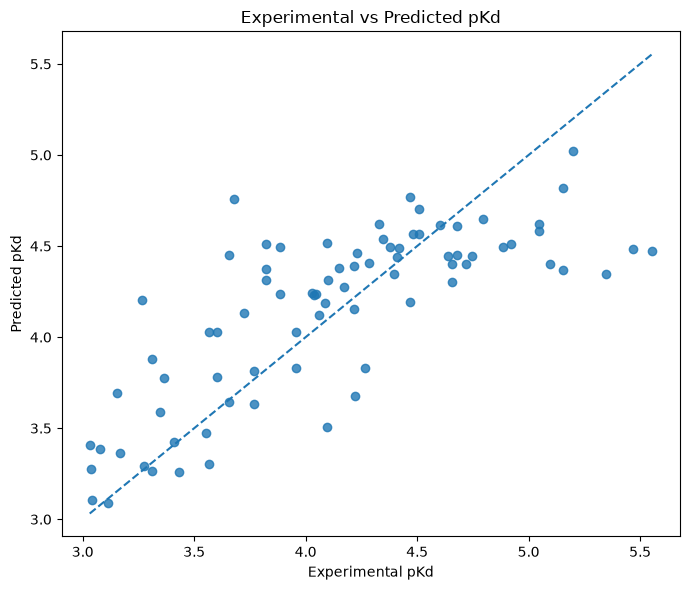

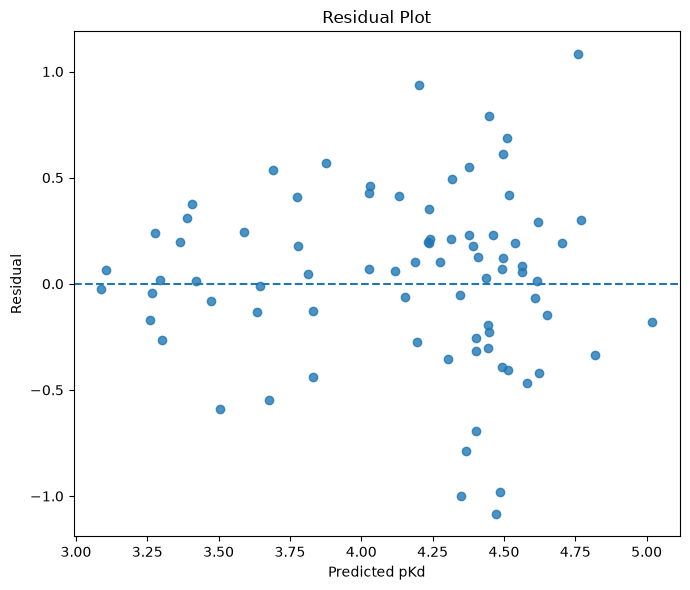

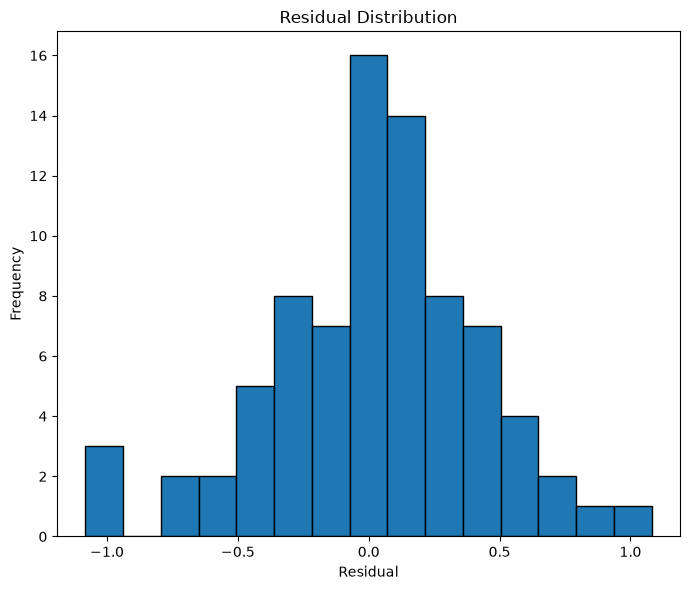

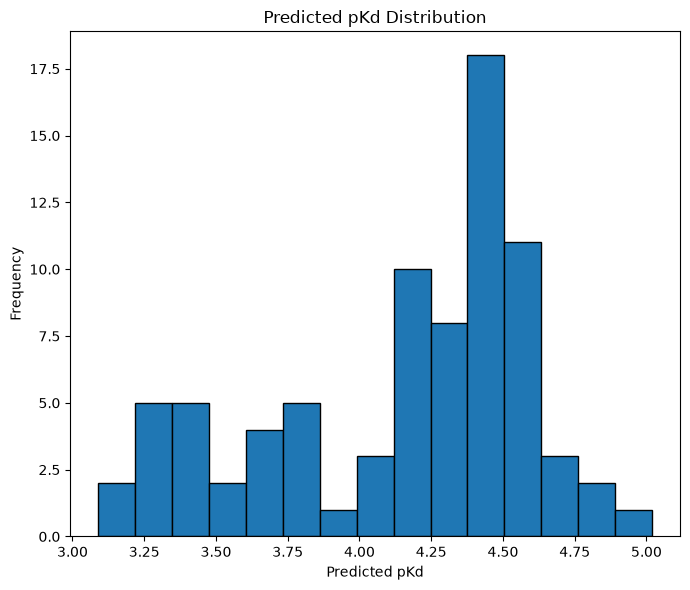

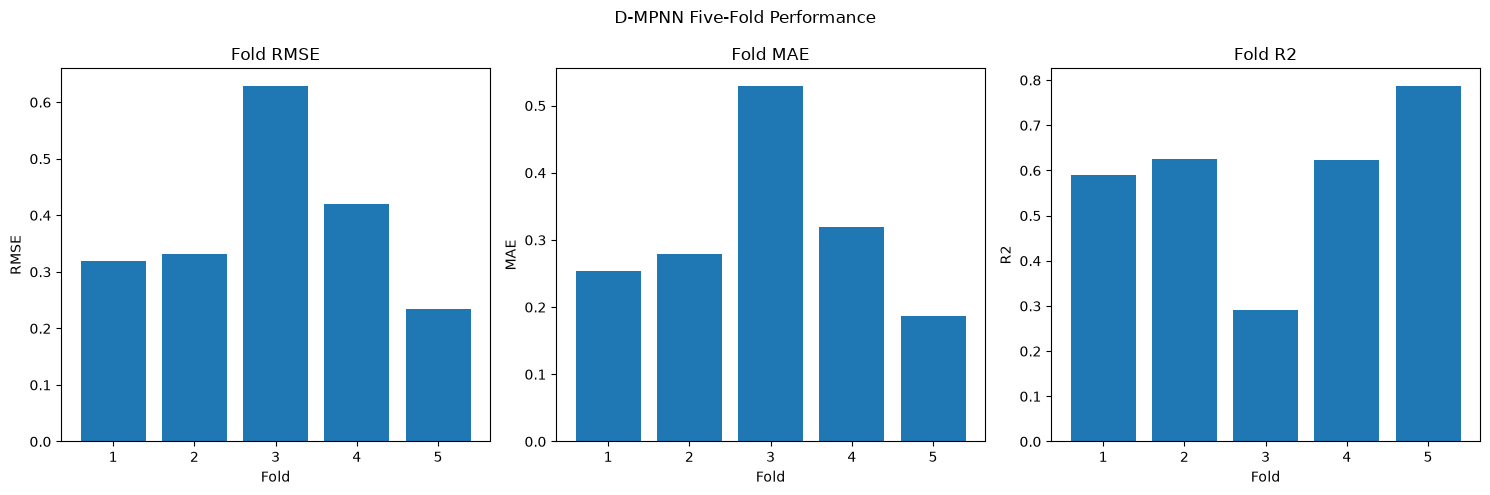


ALL OOF PLOTS SAVED
/data/Zira/Chemprop_Kd_80/DMPNN/04_Plots


In [16]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

PRED_DIR = os.path.join(BASE_DIR, "03_Predictions")
PLOT_DIR = os.path.join(BASE_DIR, "04_Plots")
RESULT_DIR = os.path.join(BASE_DIR, "05_Results")

os.makedirs(PLOT_DIR, exist_ok=True)

# Load OOF predictions
oof_df = pd.read_csv(
    os.path.join(PRED_DIR, "Seed42_OOF_Predictions.csv")
)

fold_metrics = pd.read_csv(
    os.path.join(RESULT_DIR, "Seed42_Fold_Metrics.csv")
)

y_true = oof_df["Experimental_pKd"]
y_pred = oof_df["Predicted_pKd"]
residual = oof_df["Residual"]

# 1. Experimental vs Predicted
plt.figure(figsize=(7, 6))

plt.scatter(y_true, y_pred, alpha=0.8)

min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Experimental pKd")
plt.ylabel("Predicted pKd")
plt.title("Experimental vs Predicted pKd")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "01_Experimental_vs_Predicted.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. Residual plot
plt.figure(figsize=(7, 6))

plt.scatter(y_pred, residual, alpha=0.8)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted pKd")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "02_Residual_Plot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. Residual distribution
plt.figure(figsize=(7, 6))

plt.hist(residual, bins=15, edgecolor="black")

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "03_Residual_Distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 4. Predicted pKd distribution
plt.figure(figsize=(7, 6))

plt.hist(y_pred, bins=15, edgecolor="black")

plt.xlabel("Predicted pKd")
plt.ylabel("Frequency")
plt.title("Predicted pKd Distribution")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "04_Predicted_pKd_Distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 5. Fold performance comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ["RMSE", "MAE", "R2"]

for ax, metric in zip(axes, metrics):

    ax.bar(
        fold_metrics["Fold"].astype(str),
        fold_metrics[metric]
    )

    ax.set_title(f"Fold {metric}")
    ax.set_xlabel("Fold")
    ax.set_ylabel(metric)

plt.suptitle("D-MPNN Five-Fold Performance")
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_DIR, "05_Fold_Performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nALL OOF PLOTS SAVED")
print(PLOT_DIR)


In [17]:

top10_error = (
    oof_df.sort_values(
        "Absolute_Error",
        ascending=False
    )
    .head(10)
    .copy()
)

top10_error.to_csv(
    os.path.join(
        RESULT_DIR,
        "Seed42_Top10_Absolute_Error.csv"
    ),
    index=False
)

display(
    top10_error[
        [
            "Molecule ChEMBL ID",
            "Experimental_pKd",
            "Predicted_pKd",
            "Residual",
            "Absolute_Error",
            "Fold"
        ]
    ]
)

print("\nTOP 10 ERROR SAVED")


,Molecule ChEMBL ID,Experimental_pKd,Predicted_pKd,Residual,Absolute_Error,Fold
33,CHEMBL5278336,5.552842,4.470640,-1.082202,1.082202,3
50,CHEMBL5286558,3.677781,4.758929,1.081149,1.081149,4
35,CHEMBL5410606,5.346787,4.348973,-0.997814,0.997814,3
38,CHEMBL5266862,5.468521,4.485522,-0.982999,0.982999,3
42,CHEMBL4581803,3.267606,4.202448,0.934842,0.934842,3
61,CHEMBL5274321,3.657577,4.448422,0.790845,0.790845,4
46,CHEMBL5270943,5.154902,4.367903,-0.786999,0.786999,3
37,CHEMBL5273203,5.096910,4.401578,-0.695332,0.695332,3
16,CHEMBL5276984,3.823909,4.511756,0.687847,0.687847,2
0,CHEMBL5285743,3.886057,4.495879,0.609822,0.609822,1



TOP 10 ERROR SAVED


In [18]:

import os
import pandas as pd

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

MODEL_DIR = os.path.join(
    BASE_DIR,
    "02_Models"
)

for fold in range(1, 6):

    metrics_path = os.path.join(
        MODEL_DIR,
        f"Fold{fold:02d}",
        "model_0",
        "trainer_logs",
        "version_0",
        "metrics.csv"
    )

    print("\n" + "=" * 55)
    print(f"FOLD {fold:02d} TRAINING METRICS")
    print("=" * 55)

    print("File exists:", os.path.exists(metrics_path))

    if os.path.exists(metrics_path):

        metrics_df = pd.read_csv(metrics_path)

        print("Shape:", metrics_df.shape)
        print("Columns:", metrics_df.columns.tolist())

        display(metrics_df.head(5))

    else:
        print("Metrics file not found.")



FOLD 01 TRAINING METRICS
File exists: True
Shape: (139, 8)
Columns: ['epoch', 'step', 'train_loss_epoch', 'train_loss_step', 'val/mae', 'val/r2', 'val/rmse', 'val_loss']


,epoch,step,train_loss_epoch,train_loss_step,val/mae,val/r2,val/rmse,val_loss
0,0,3,NaN,NaN,0.713912,-0.305081,0.874946,0.765531
1,0,3,0.989854,NaN,NaN,NaN,NaN,NaN
2,1,7,NaN,NaN,0.772643,-0.454657,0.923726,0.853269
3,1,7,0.968332,NaN,NaN,NaN,NaN,NaN
4,2,11,NaN,NaN,0.762683,-0.414182,0.910784,0.829527



FOLD 02 TRAINING METRICS
File exists: True
Shape: (124, 8)
Columns: ['epoch', 'step', 'train_loss_epoch', 'train_loss_step', 'val/mae', 'val/r2', 'val/rmse', 'val_loss']


,epoch,step,train_loss_epoch,train_loss_step,val/mae,val/r2,val/rmse,val_loss
0,0,3,NaN,NaN,0.703542,-0.021296,0.836682,0.700037
1,0,3,0.991617,NaN,NaN,NaN,NaN,NaN
2,1,7,NaN,NaN,0.694435,-0.023814,0.837713,0.701763
3,1,7,0.979988,NaN,NaN,NaN,NaN,NaN
4,2,11,NaN,NaN,0.696514,-0.016611,0.834761,0.696826



FOLD 03 TRAINING METRICS
File exists: True
Shape: (137, 8)
Columns: ['epoch', 'step', 'train_loss_epoch', 'train_loss_step', 'val/mae', 'val/r2', 'val/rmse', 'val_loss']


,epoch,step,train_loss_epoch,train_loss_step,val/mae,val/r2,val/rmse,val_loss
0,0,3,NaN,NaN,1.172645,-0.172834,1.403903,1.970942
1,0,3,0.990232,NaN,NaN,NaN,NaN,NaN
2,1,7,NaN,NaN,1.131603,-0.093393,1.355523,1.837442
3,1,7,0.970598,NaN,NaN,NaN,NaN,NaN
4,2,11,NaN,NaN,1.100744,-0.030098,1.315703,1.731075



FOLD 04 TRAINING METRICS
File exists: True
Shape: (208, 8)
Columns: ['epoch', 'step', 'train_loss_epoch', 'train_loss_step', 'val/mae', 'val/r2', 'val/rmse', 'val_loss']


,epoch,step,train_loss_epoch,train_loss_step,val/mae,val/r2,val/rmse,val_loss
0,0,3,NaN,NaN,1.007253,-0.064845,1.153950,1.331600
1,0,3,0.988879,NaN,NaN,NaN,NaN,NaN
2,1,7,NaN,NaN,1.020974,-0.111615,1.179019,1.390085
3,1,7,0.964199,NaN,NaN,NaN,NaN,NaN
4,2,11,NaN,NaN,1.006873,-0.075397,1.159653,1.344795



FOLD 05 TRAINING METRICS
File exists: True
Shape: (208, 8)
Columns: ['epoch', 'step', 'train_loss_epoch', 'train_loss_step', 'val/mae', 'val/r2', 'val/rmse', 'val_loss']


,epoch,step,train_loss_epoch,train_loss_step,val/mae,val/r2,val/rmse,val_loss
0,0,3,NaN,NaN,0.616642,-0.011965,0.780092,0.608543
1,0,3,0.988645,NaN,NaN,NaN,NaN,NaN
2,1,7,NaN,NaN,0.572393,0.068989,0.748239,0.559862
3,1,7,0.975414,NaN,NaN,NaN,NaN,NaN
4,2,11,NaN,NaN,0.554607,0.115737,0.729212,0.531750


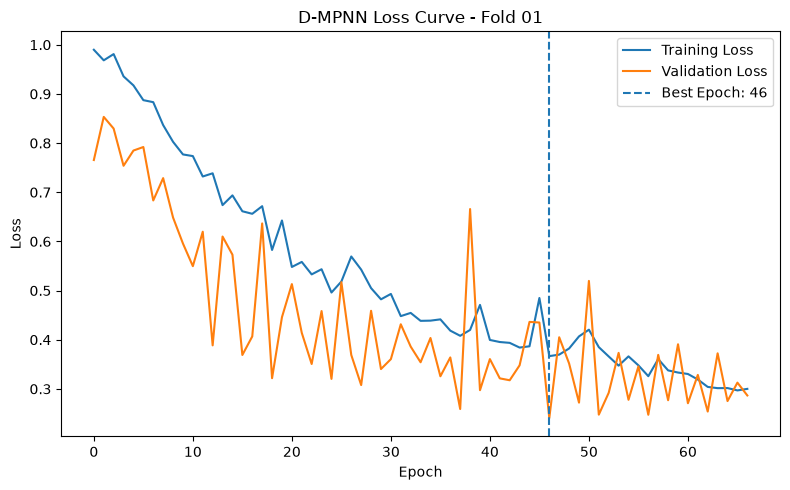

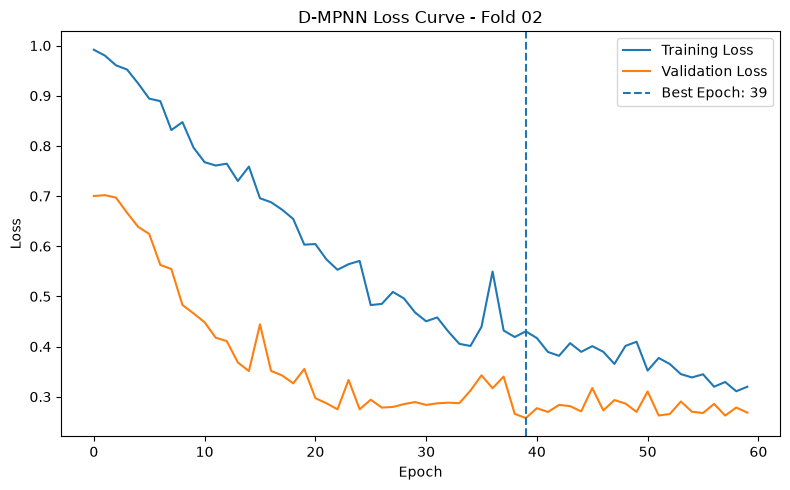

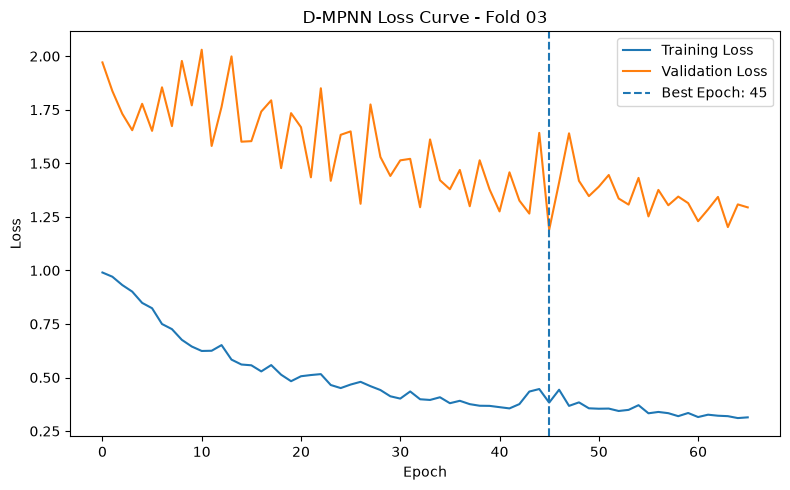

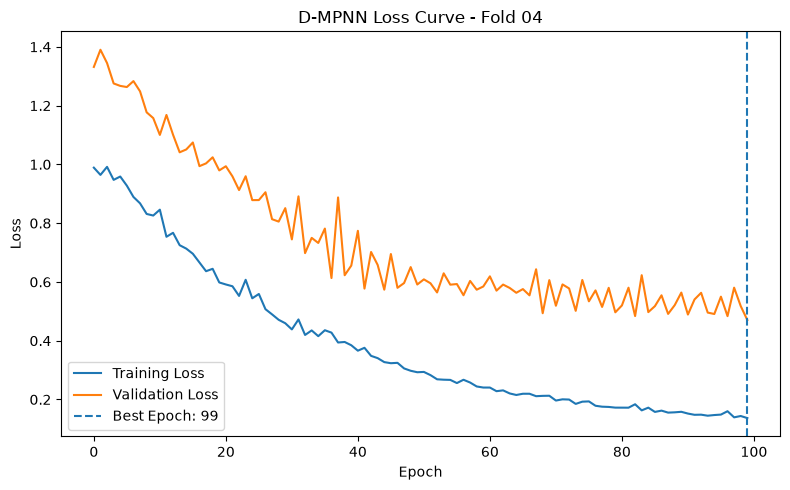

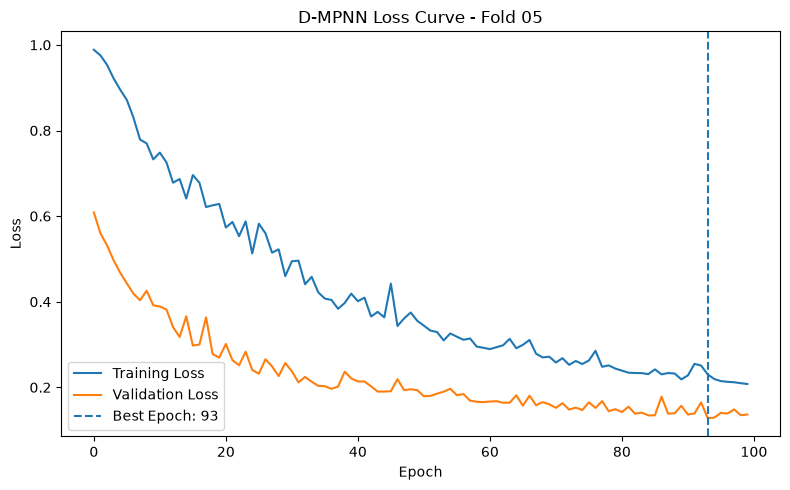

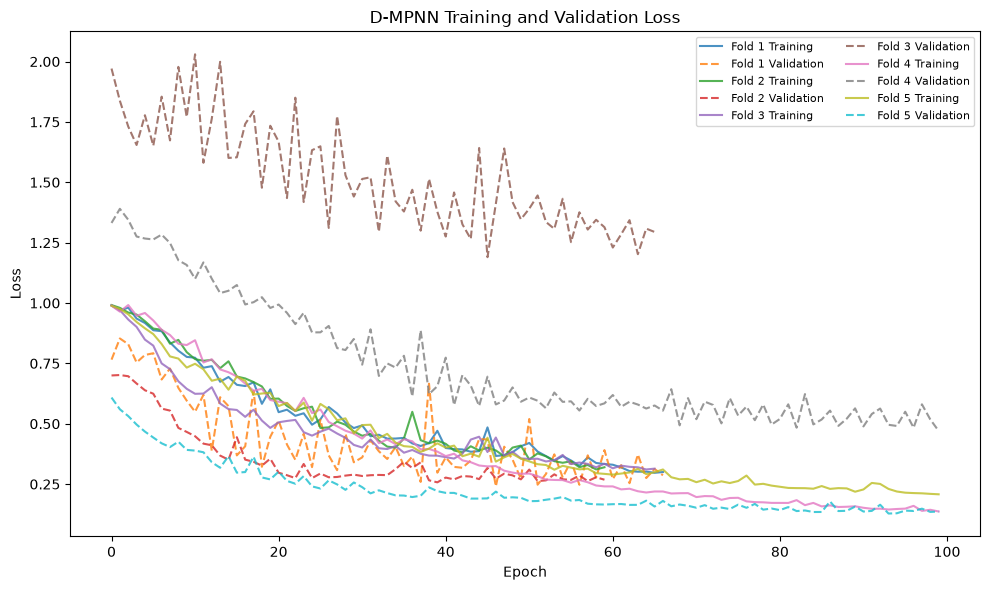


BEST EPOCH SUMMARY


,Fold,Best_Epoch,Best_Val_Loss,Best_Val_RMSE,Best_Val_MAE,Best_Val_R2
0,1,46,0.240641,0.490552,0.390938,0.589754
1,2,39,0.257410,0.507356,0.429058,0.624460
2,3,45,1.189888,1.090820,0.918211,0.291942
3,4,99,0.470386,0.685847,0.519674,0.623845
4,5,93,0.128200,0.358050,0.284928,0.786813



LOSS CURVES SAVED
/data/Zira/Chemprop_Kd_80/DMPNN/04_Plots


In [19]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

MODEL_DIR = os.path.join(BASE_DIR, "02_Models")
PLOT_DIR = os.path.join(BASE_DIR, "04_Plots")
RESULT_DIR = os.path.join(BASE_DIR, "05_Results")

os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

all_histories = []
best_epochs = []

for fold in range(1, 6):

    metrics_path = os.path.join(
        MODEL_DIR,
        f"Fold{fold:02d}",
        "model_0",
        "trainer_logs",
        "version_0",
        "metrics.csv"
    )

    df = pd.read_csv(metrics_path)

    # Separate training and validation records
    train_history = df[
        df["train_loss_epoch"].notna()
    ][["epoch", "train_loss_epoch"]].copy()

    val_history = df[
        df["val_loss"].notna()
    ][["epoch", "val_loss", "val/rmse", "val/mae", "val/r2"]].copy()

    train_history = train_history.sort_values("epoch")
    val_history = val_history.sort_values("epoch")

    # Best epoch based on validation loss
    best_idx = val_history["val_loss"].idxmin()
    best_row = val_history.loc[best_idx]

    best_epochs.append({
        "Fold": fold,
        "Best_Epoch": int(best_row["epoch"]),
        "Best_Val_Loss": best_row["val_loss"],
        "Best_Val_RMSE": best_row["val/rmse"],
        "Best_Val_MAE": best_row["val/mae"],
        "Best_Val_R2": best_row["val/r2"]
    })

    # Individual fold plot
    plt.figure(figsize=(8, 5))

    plt.plot(
        train_history["epoch"],
        train_history["train_loss_epoch"],
        label="Training Loss"
    )

    plt.plot(
        val_history["epoch"],
        val_history["val_loss"],
        label="Validation Loss"
    )

    plt.axvline(
        best_row["epoch"],
        linestyle="--",
        label=f"Best Epoch: {int(best_row['epoch'])}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"D-MPNN Loss Curve - Fold {fold:02d}")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            PLOT_DIR,
            f"06_Loss_Curve_Fold{fold:02d}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    train_history["Fold"] = fold
    val_history["Fold"] = fold

    all_histories.append({
        "train": train_history,
        "validation": val_history
    })


# Combined five-fold loss plot
plt.figure(figsize=(10, 6))

for fold, history in enumerate(all_histories, start=1):

    plt.plot(
        history["train"]["epoch"],
        history["train"]["train_loss_epoch"],
        label=f"Fold {fold} Training",
        alpha=0.8
    )

    plt.plot(
        history["validation"]["epoch"],
        history["validation"]["val_loss"],
        linestyle="--",
        label=f"Fold {fold} Validation",
        alpha=0.8
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("D-MPNN Training and Validation Loss")
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(
        PLOT_DIR,
        "07_Combined_Training_Validation_Loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Save best epoch summary
best_epochs_df = pd.DataFrame(best_epochs)

best_epochs_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "Seed42_Best_Epoch_Summary.csv"
    ),
    index=False
)

print("\nBEST EPOCH SUMMARY")
display(best_epochs_df)

print("\nLOSS CURVES SAVED")
print(PLOT_DIR)


In [20]:

import os
import pandas as pd
import json

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

DATA_PATH = os.path.join(
    BASE_DIR,
    "00_Dataset",
    "USP5_Kd_80_fixed.csv"
)

FINAL_DIR = os.path.join(
    BASE_DIR,
    "06_Final_Model"
)

os.makedirs(FINAL_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("=" * 55)
print("FINAL MODEL PREPARATION")
print("=" * 55)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

print("\npKd statistics:")
display(df["pKd"].describe())

assert len(df) == 80
assert df["Smiles"].notna().all()
assert df["pKd"].notna().all()

# Save final training dataset
final_dataset_path = os.path.join(
    FINAL_DIR,
    "USP5_Final_Training_80.csv"
)

df.to_csv(final_dataset_path, index=False)

# Save final model configuration
final_config = {
    "architecture": "D-MPNN",
    "task": "regression",
    "target": "pKd",
    "hidden_dim": 300,
    "depth": 3,
    "dropout": 0.0,
    "batch_size": 16,
    "epochs": 46,
    "aggregation": "norm",
    "aggregation_norm": 100,
    "featurizer": "V2",
    "pytorch_seed": 42,
    "accelerator": "gpu",
    "devices": 1,
    "training_compounds": 80,
    "epoch_selection": "Median of five validation best epochs"
}

with open(
    os.path.join(FINAL_DIR, "Final_Model_Config.json"),
    "w"
) as f:
    json.dump(final_config, f, indent=4)

print("\nFINAL DATASET SAVED")
print(final_dataset_path)

print("\nFINAL CONFIGURATION SAVED")
print(FINAL_DIR)

print("\nREADY FOR FINAL D-MPNN TRAINING")


FINAL MODEL PREPARATION
Dataset shape: (80, 3)
Columns: ['Molecule ChEMBL ID', 'Smiles', 'pKd']

Missing values:
Molecule ChEMBL ID    0
Smiles                0
pKd                   0
dtype: int64

pKd statistics:


count    80.000000
mean      4.121417
std       0.636259
min       3.031517
25%       3.643698
50%       4.099641
75%       4.531994
max       5.552842
Name: pKd, dtype: float64


FINAL DATASET SAVED
/data/Zira/Chemprop_Kd_80/DMPNN/06_Final_Model/USP5_Final_Training_80.csv

FINAL CONFIGURATION SAVED
/data/Zira/Chemprop_Kd_80/DMPNN/06_Final_Model

READY FOR FINAL D-MPNN TRAINING


In [21]:

import sys
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "-c",
        "from chemprop.cli.main import main; main()",
        "train",
        "--help"
    ],
    capture_output=True,
    text=True
)

help_text = result.stdout + result.stderr

keywords = [
    "split-sizes",
    "separate-val-path",
    "splits-file",
    "epochs",
    "patience",
    "tracking-metric",
    "data-path"
]

print("=" * 60)
print("FINAL TRAINING CLI CHECK")
print("=" * 60)

for keyword in keywords:
    print(f"\n[{keyword}]")

    matching = [
        line.strip()
        for line in help_text.splitlines()
        if keyword in line.lower()
    ]

    for line in matching:
        print(line)

print("\nCLI CHECK COMPLETED")


FINAL TRAINING CLI CHECK

[split-sizes]
[--split-sizes SPLIT_SIZES SPLIT_SIZES SPLIT_SIZES]
--split-sizes SPLIT_SIZES SPLIT_SIZES SPLIT_SIZES

[separate-val-path]

[splits-file]
[--splits-file SPLITS_FILE] [--data-seed DATA_SEED]
--splits-file SPLITS_FILE

[epochs]
[--warmup-epochs WARMUP_EPOCHS] [--init-lr INIT_LR]
[--max-lr MAX_LR] [--final-lr FINAL_LR] [--epochs EPOCHS]
--warmup-epochs WARMUP_EPOCHS
Number of epochs during which learning rate increases
--epochs EPOCHS       Number of epochs to train over
--patience PATIENCE   Number of epochs to wait for improvement before early

[patience]
[--patience PATIENCE] [--min-delta MIN_DELTA]
--patience PATIENCE   Number of epochs to wait for improvement before early

[tracking-metric]
[--tracking-metric TRACKING_METRIC] [--show-individual-scores]
--tracking-metric TRACKING_METRIC

[data-path]
-i [DATA_PATH ...], --data-path [DATA_PATH ...]

CLI CHECK COMPLETED


In [22]:

import os
import json
import pandas as pd

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FINAL_DIR = os.path.join(
    BASE_DIR,
    "06_Final_Model"
)

DATA_PATH = os.path.join(
    FINAL_DIR,
    "USP5_Final_Training_80.csv"
)

os.makedirs(FINAL_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)

# All 80 compounds assigned to training
final_splits = [
    {
        "train": list(range(len(df)))
    }
]

SPLIT_PATH = os.path.join(
    FINAL_DIR,
    "Final_80_Training_Splits.json"
)

with open(SPLIT_PATH, "w") as f:
    json.dump(final_splits, f, indent=4)

# Verify split
with open(SPLIT_PATH) as f:
    check = json.load(f)

train_indices = check[0]["train"]

print("=" * 55)
print("FINAL TRAINING SPLIT VALIDATION")
print("=" * 55)

print("Total compounds:", len(df))
print("Training compounds:", len(train_indices))
print("Validation compounds: 0")
print("Test compounds: 0")

print("Unique training indices:", len(set(train_indices)))

assert len(train_indices) == 80
assert len(set(train_indices)) == 80
assert min(train_indices) == 0
assert max(train_indices) == 79

print("\nSPLIT VALIDATION SUCCESSFUL")
print("\nSplit file saved:")
print(SPLIT_PATH)


FINAL TRAINING SPLIT VALIDATION
Total compounds: 80
Training compounds: 80
Validation compounds: 0
Test compounds: 0
Unique training indices: 80

SPLIT VALIDATION SUCCESSFUL

Split file saved:
/data/Zira/Chemprop_Kd_80/DMPNN/06_Final_Model/Final_80_Training_Splits.json


In [23]:

import os
import sys
import subprocess

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

FINAL_DIR = os.path.join(
    BASE_DIR,
    "06_Final_Model"
)

DATA_PATH = os.path.join(
    FINAL_DIR,
    "USP5_Final_Training_80.csv"
)

SPLIT_PATH = os.path.join(
    FINAL_DIR,
    "Final_80_Training_Splits.json"
)

OUTPUT_DIR = os.path.join(
    FINAL_DIR,
    "Chemprop_Final_Model"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.exists(DATA_PATH)
assert os.path.exists(SPLIT_PATH)

command = [
    sys.executable,
    "-c",
    "from chemprop.cli.main import main; main()",
    "train",

    "--data-path", DATA_PATH,
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",

    "--task-type", "regression",

    "--multi-hot-atom-featurizer-mode", "V2",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.0",

    "--aggregation", "norm",
    "--aggregation-norm", "100",

    "--batch-size", "16",
    "--epochs", "46",

    "--pytorch-seed", "42",
    "--accelerator", "gpu",
    "--devices", "1",

    "--splits-file", SPLIT_PATH,

    "--output-dir", OUTPUT_DIR
]

print("=" * 60)
print("FINAL D-MPNN TRAINING")
print("=" * 60)

print("Dataset:", DATA_PATH)
print("Training compounds: 80")
print("Epochs: 46")
print("Output:", OUTPUT_DIR)

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

log_path = os.path.join(
    OUTPUT_DIR,
    "final_training_log.txt"
)

with open(log_path, "w") as f:
    f.write(result.stdout)
    f.write("\n\nSTDERR:\n")
    f.write(result.stderr)

print("\nRETURN CODE:", result.returncode)
print("\nTRAINING OUTPUT:")
print(result.stdout[-8000:])

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-4000:])

print("\nLOG SAVED:", log_path)

print("\nFINAL TRAINING FINISHED")


FINAL D-MPNN TRAINING
Dataset: /data/Zira/Chemprop_Kd_80/DMPNN/06_Final_Model/USP5_Final_Training_80.csv
Training compounds: 80
Epochs: 46
Output: /data/Zira/Chemprop_Kd_80/DMPNN/06_Final_Model/Chemprop_Final_Model

RETURN CODE: 0

TRAINING OUTPUT:
                         0.404             
                                                              train_loss_epoch: 
                                                              0.410             
Epoch 43/45 ━━━━━━━━━━━━━━━━━ 5/5 0:00:00 • 0:00:00 84.08it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.453             
                                                              train_loss_epoch: 
                                                              0.404             
Epoch 44/45 ━━━━━━━━━━━━━━━━━━ 0/5 0:00:00 • 0:00:00 0.00it/s v_num: 0.000      
                                                           

In [24]:

import os
import torch

MODEL_PATH = (
    "/data/Zira/Chemprop_Kd_80/DMPNN/"
    "06_Final_Model/Chemprop_Final_Model/"
    "model_0/best.pt"
)

print("=" * 55)
print("FINAL MODEL CHECKPOINT VERIFICATION")
print("=" * 55)

print("Model exists:", os.path.exists(MODEL_PATH))

if os.path.exists(MODEL_PATH):

    size_mb = os.path.getsize(MODEL_PATH) / (1024**2)

    print("Model size:", round(size_mb, 2), "MB")
    print("Checkpoint:", MODEL_PATH)

    print("\nFINAL MODEL READY FOR SCREENING")

else:
    print("\nMODEL CHECKPOINT NOT FOUND")


FINAL MODEL CHECKPOINT VERIFICATION
Model exists: True
Model size: 1.22 MB
Checkpoint: /data/Zira/Chemprop_Kd_80/DMPNN/06_Final_Model/Chemprop_Final_Model/model_0/best.pt

FINAL MODEL READY FOR SCREENING


In [25]:

import os
import pandas as pd
import numpy as np

from rdkit import Chem

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

SCREEN_DIR = os.path.join(
    BASE_DIR,
    "07_Screening"
)

VALIDATION_DIR = os.path.join(
    SCREEN_DIR,
    "01_Dataset_Validation"
)

os.makedirs(VALIDATION_DIR, exist_ok=True)

# GitHub dataset
SCREENING_URL = (
    "https://raw.githubusercontent.com/"
    "devitanuraljazira/USP5/refs/heads/main/"
    "hasil%20skrining.csv"
)

# Read directly from GitHub
screen_df = pd.read_csv(SCREENING_URL)

print("=" * 60)
print("USP5 SCREENING DATASET")
print("=" * 60)

print("Dataset shape:", screen_df.shape)
print("Total candidates:", len(screen_df))

print("\nDataset columns:")
for col in screen_df.columns:
    print("-", col)

print("\nDataset preview:")
display(screen_df.head())

print("\nDataset information:")
screen_df.info()

# Check required columns
required_columns = [
    "Compound ChEMBL ID",
    "Smiles"
]

for col in required_columns:
    assert col in screen_df.columns, (
        f"Required column missing: {col}"
    )

print("\nDATASET SUCCESSFULLY LOADED")


USP5 SCREENING DATASET
Dataset shape: (991, 9)
Total candidates: 991

Dataset columns:
- Compound ChEMBL ID
- Smiles
- Smiles (RDKit Mol)
- SlogP
- TPSA
- ExactMW
- NumHBD
- NumHBA
- Lipinski_RO5

Dataset preview:


,Compound ChEMBL ID,Smiles,Smiles (RDKit Mol),SlogP,TPSA,ExactMW,NumHBD,NumHBA,Lipinski_RO5
0,CHEMBL151562,C/N=C(\N)c1ccc(/C=C2/CCCC/C(=C/c3ccc(C(=N)N)cc...,C/N=C(\N)c1ccc(/C=C2/CCCC/C(=C/c3ccc(C(=N)N)cc...,3.91587,105.32,386.210661,3,3,Pass
1,CHEMBL1630638,O=C1/C(=C/c2ccc(N3CCOCC3)cc2)CC/C1=C\c1ccc(N2C...,O=C1/C(=C/c2ccc(N3CCOCC3)cc2)CC/C1=C\c1ccc(N2C...,4.18970,42.01,430.225643,0,5,Pass
2,CHEMBL150612,N=C(N)c1ccc(/C=C2/CC(c3ccccc3)C/C(=C\c3ccc(C(=...,N=C(N)c1ccc(/C=C2/CC(c3ccccc3)C/C(=C\c3ccc(C(=...,4.86844,116.81,434.210661,4,3,Pass
3,CHEMBL457298,O=C(/C=C/c1ccc([N+](=O)[O-])cc1)/C=C/c1ccc([N+...,O=C(/C=C/c1ccc([N+](=O)[O-])cc1)/C=C/c1ccc([N+...,3.79870,103.35,324.074621,0,5,Pass
4,CHEMBL423698,COc1ccc(/C=C/C(=O)/C=C/c2ccc(OC)c(OC)c2)cc1OC,COc1ccc(/C=C/C(=O)/C=C/c2ccc(OC)c(OC)c2)cc1OC,4.01670,53.99,354.146724,0,5,Pass



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 991 entries, 0 to 990
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Compound ChEMBL ID  991 non-null    str    
 1   Smiles              991 non-null    str    
 2   Smiles (RDKit Mol)  991 non-null    str    
 3   SlogP               991 non-null    float64
 4   TPSA                991 non-null    float64
 5   ExactMW             991 non-null    float64
 6   NumHBD              991 non-null    int64  
 7   NumHBA              991 non-null    int64  
 8   Lipinski_RO5        991 non-null    str    
dtypes: float64(3), int64(2), str(4)
memory usage: 69.8 KB

DATASET SUCCESSFULLY LOADED


In [26]:

# Validate SMILES using RDKit

def validate_smiles(smiles):

    if pd.isna(smiles):
        return False

    mol = Chem.MolFromSmiles(str(smiles))

    return mol is not None


screen_df["SMILES_Valid"] = (
    screen_df["Smiles"].apply(validate_smiles)
)

screen_df["Canonical_SMILES"] = screen_df["Smiles"].apply(
    lambda x: Chem.MolToSmiles(
        Chem.MolFromSmiles(str(x)),
        canonical=True
    ) if pd.notna(x) and Chem.MolFromSmiles(str(x)) else None
)

total_candidates = len(screen_df)

valid_count = int(screen_df["SMILES_Valid"].sum())

invalid_count = total_candidates - valid_count

missing_smiles = int(screen_df["Smiles"].isna().sum())

duplicate_smiles = int(
    screen_df["Canonical_SMILES"].dropna().duplicated().sum()
)

print("=" * 60)
print("SCREENING SMILES VALIDATION")
print("=" * 60)

print("Total candidates:", total_candidates)
print("Valid SMILES:", valid_count)
print("Invalid SMILES:", invalid_count)
print("Missing SMILES:", missing_smiles)
print("Canonical SMILES duplicates:", duplicate_smiles)

# Validation summary
validation_summary = pd.DataFrame({
    "Parameter": [
        "Total Candidates",
        "Valid SMILES",
        "Invalid SMILES",
        "Missing SMILES",
        "Canonical SMILES Duplicates"
    ],
    "Value": [
        total_candidates,
        valid_count,
        invalid_count,
        missing_smiles,
        duplicate_smiles
    ]
})

display(validation_summary)

# Save validation files
screen_df.to_csv(
    os.path.join(
        VALIDATION_DIR,
        "USP5_Screening_Validation_All.csv"
    ),
    index=False
)

valid_df = screen_df[
    screen_df["SMILES_Valid"]
].copy()

valid_df.to_csv(
    os.path.join(
        VALIDATION_DIR,
        "USP5_Screening_Valid.csv"
    ),
    index=False
)

invalid_df = screen_df[
    ~screen_df["SMILES_Valid"]
].copy()

invalid_df.to_csv(
    os.path.join(
        VALIDATION_DIR,
        "USP5_Screening_Invalid.csv"
    ),
    index=False
)

validation_summary.to_csv(
    os.path.join(
        VALIDATION_DIR,
        "USP5_Screening_Validation_Summary.csv"
    ),
    index=False
)

print("\nVALIDATION FILES SAVED")
print(VALIDATION_DIR)

print("\nVALID CANDIDATES:", len(valid_df))
print("INVALID CANDIDATES:", len(invalid_df))


SCREENING SMILES VALIDATION
Total candidates: 991
Valid SMILES: 991
Invalid SMILES: 0
Missing SMILES: 0
Canonical SMILES duplicates: 0


,Parameter,Value
0,Total Candidates,991
1,Valid SMILES,991
2,Invalid SMILES,0
3,Missing SMILES,0
4,Canonical SMILES Duplicates,0



VALIDATION FILES SAVED
/data/Zira/Chemprop_Kd_80/DMPNN/07_Screening/01_Dataset_Validation

VALID CANDIDATES: 991
INVALID CANDIDATES: 0


In [27]:

import os
import pandas as pd
import subprocess
import sys

BASE_DIR = "/data/Zira/Chemprop_Kd_80/DMPNN"

SCREEN_DIR = os.path.join(
    BASE_DIR,
    "07_Screening"
)

VALIDATION_DIR = os.path.join(
    SCREEN_DIR,
    "01_Dataset_Validation"
)

PREDICTION_DIR = os.path.join(
    SCREEN_DIR,
    "02_Predictions"
)

os.makedirs(PREDICTION_DIR, exist_ok=True)

# Input dataset
INPUT_PATH = os.path.join(
    VALIDATION_DIR,
    "USP5_Screening_Valid.csv"
)

# Final model checkpoint
MODEL_PATH = os.path.join(
    BASE_DIR,
    "06_Final_Model",
    "Chemprop_Final_Model",
    "model_0",
    "best.pt"
)

# Prepare prediction input
screen_df = pd.read_csv(INPUT_PATH)

predict_df = screen_df[
    ["Compound ChEMBL ID", "Smiles"]
].copy()

predict_df = predict_df.rename(
    columns={"Smiles": "Smiles"}
)

PREDICT_INPUT = os.path.join(
    PREDICTION_DIR,
    "USP5_Screening_Prediction_Input.csv"
)

predict_df[["Smiles"]].to_csv(
    PREDICT_INPUT,
    index=False
)

print("PREDICTION PREPARATION")
print("=" * 50)

print("Candidates:", len(predict_df))
print("Input file:", PREDICT_INPUT)
print("Model exists:", os.path.exists(MODEL_PATH))

assert len(predict_df) == 991
assert os.path.exists(MODEL_PATH)

print("\nPREDICTION INPUT READY")


PREDICTION PREPARATION
Candidates: 991
Input file: /data/Zira/Chemprop_Kd_80/DMPNN/07_Screening/02_Predictions/USP5_Screening_Prediction_Input.csv
Model exists: True

PREDICTION INPUT READY


In [28]:

import os
import subprocess
import sys

PREDICT_OUTPUT = os.path.join(
    PREDICTION_DIR,
    "Chemprop_Predictions"
)

os.makedirs(PREDICT_OUTPUT, exist_ok=True)

command = [
    sys.executable,
    "-c",
    "from chemprop.cli.main import main; main()",
    "predict",

    "--test-path", PREDICT_INPUT,
    "--smiles-columns", "Smiles",
    "--model-path", MODEL_PATH,
    "--preds-path",
    os.path.join(
        PREDICT_OUTPUT,
        "USP5_DMPNN_Predictions.csv"
    )
]

print("=" * 55)
print("D-MPNN SCREENING PREDICTION")
print("=" * 55)

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nSTDOUT:")
print(result.stdout[-5000:])

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-3000:])

print("\nPREDICTION PROCESS COMPLETED")


D-MPNN SCREENING PREDICTION
Return code: 0

STDOUT:

Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/16 0:00:00 • -:--:-- 0.00it/s 
Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/16 0:00:00 • -:--:-- 0.00it/s 
Predicting ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/16 0:00:00 • -:--:-- 0.00it/s 
Predicting ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/16 0:00:00 • 0:00:01 22.72it/s 
Predicting ━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/16 0:00:00 • 0:00:01 23.52it/s 
Predicting ━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━ 4/16 0:00:00 • 0:00:01 23.68it/s 
Predicting ━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━ 5/16 0:00:00 • 0:00:01 23.56it/s 
Predicting ━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━ 6/16 0:00:00 • 0:00:01 23.65it/s 
Predicting ━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━ 7/16 0:00:00 • 0:00:01 23.69it/s 
Predicting ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━ 8/16 0:00:00 • 0:00:01 23.81it/s 
Predicting ━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━ 9/16 0:00:00 • 0:00:01 23.88it/s 
Predicting ━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━ 10/16 0:00:00 • 0:00:0